# Telecom Customer Retention

**Question.** How does estimated retention vary across payment methods in the [IBM Telco Customer Churn sample](https://github.com/IBM/watsonx-ai-samples/blob/master/cpd4.5/data/customer_churn/WA_FnUseC_TelcoCustomerChurn.csv)?

A Kaplan–Meier estimate treats churn as the event. Customers who were still active are right-censored at their recorded tenure.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from lifelines import KaplanMeierFitter

plt.style.use("seaborn-v0_8-whitegrid")
data_dir = Path("../data") if Path("../data").is_dir() else Path("data")
data = pd.read_csv(data_dir / "telco-churn.csv", usecols=["tenure", "Churn", "PaymentMethod"])
assert not data.isna().any().any()
assert data["Churn"].isin(["Yes", "No"]).all()
assert data["tenure"].ge(0).all()
data["churned"] = data["Churn"].eq("Yes")
print(f"{len(data):,} customers across {data['PaymentMethod'].nunique()} payment methods")

7,043 customers across 4 payment methods


,Customers,Observed churns,12-month retention (%),24-month retention (%)
Payment method,,,,
Credit card (automatic),1522,232,94.5,91.3
Bank transfer (automatic),1544,258,93.1,90.2
Mailed check,1612,308,82.8,79.7
Electronic check,2365,1071,72.7,62.4


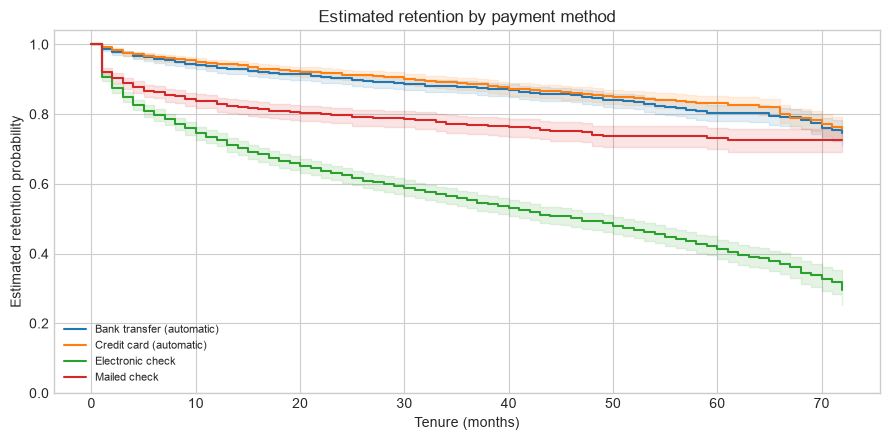

Highest estimated 12-month retention: Credit card (automatic)


In [2]:
fig, ax = plt.subplots(figsize=(9, 4.5))
rows = []
for payment_method, cohort in data.groupby("PaymentMethod", sort=True):
    km = KaplanMeierFitter().fit(cohort["tenure"], event_observed=cohort["churned"], label=payment_method)
    km.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.12)
    rows.append({
        "Payment method": payment_method,
        "Customers": len(cohort),
        "Observed churns": int(cohort["churned"].sum()),
        "12-month retention (%)": 100 * km.predict(12),
        "24-month retention (%)": 100 * km.predict(24),
    })

summary = pd.DataFrame(rows).set_index("Payment method").sort_values("12-month retention (%)", ascending=False)
assert summary["Customers"].sum() == len(data)
assert summary["12-month retention (%)"].ge(summary["24-month retention (%)"]).all()
display(summary.round(1))
ax.set(title="Estimated retention by payment method", xlabel="Tenure (months)", ylabel="Estimated retention probability", ylim=(0, 1.04))
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"Highest estimated 12-month retention: {summary.index[0]}")

**Interpretation.** The curves show unadjusted associations. Payment method can be related to factors such as contract type, so the estimates do not establish a causal effect of switching payment method.